# Notebook 02: Visualización exploratoria
**Proyecto final: emisiones de CO₂ per cápita (Our World in Data)** · Responsable: Julian

Este notebook usa los datos que dejó el notebook 01 (`../data/co2_limpio_2019.csv`) y el dataset completo para las series de tiempo.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

AZUL = "#2a6fbb"      # color principal de datos
GRIS = "#8a8f98"      # contexto / comparaciones
ROJO = "#c8452f"      # resaltar un caso o la recta del modelo
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10,
})

ANIO = 2019   # mismo año de análisis que el notebook 01

df = pd.read_csv("../data/owid-co2-data.csv")          # dataset completo (series de tiempo)
limpio = pd.read_csv("../data/co2_limpio_2019.csv")    # países con datos completos en ANIO (salida del notebook 01)
print(f"Dataset completo: {df.shape[0]:,} filas | Dataset limpio: {limpio.shape[0]} países")

Matplotlib is building the font cache; this may take a moment.


Dataset completo: 56,269 filas | Dataset limpio: 164 países


Antes de modelar, se visualizan los datos para entender qué patrones existen.

## 2.1 Evolución de las emisiones mundiales

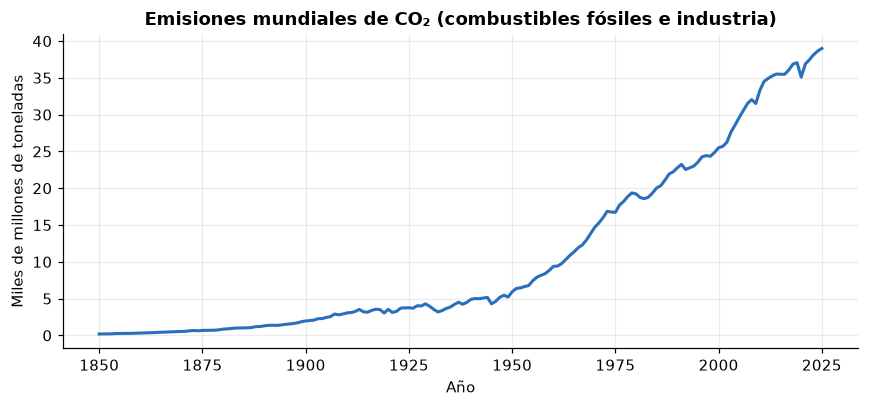

In [2]:
mundo = df[df["country"] == "World"].dropna(subset=["co2"])
mundo = mundo[mundo["year"] >= 1850]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(mundo["year"], mundo["co2"] / 1000, color=AZUL, lw=2)
ax.set_title("Emisiones mundiales de CO₂ (combustibles fósiles e industria)")
ax.set_ylabel("Miles de millones de toneladas")
ax.set_xlabel("Año")
plt.tight_layout(); plt.show()

## 2.2 ¿Quién emite más? Total frente a per cápita

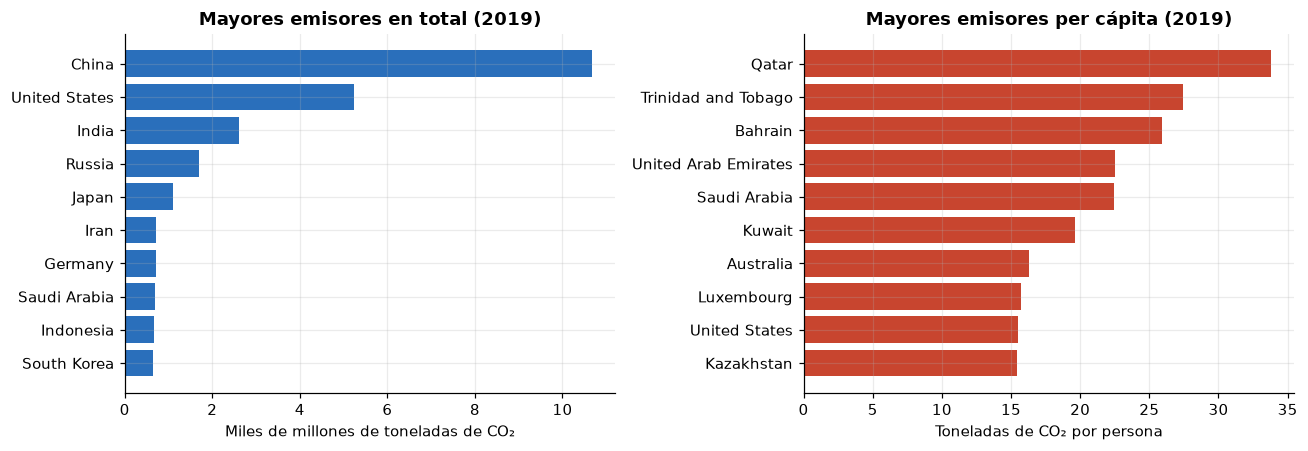

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

top_total = limpio.nlargest(10, "co2").sort_values("co2")
axes[0].barh(top_total["country"], top_total["co2"] / 1000, color=AZUL)
axes[0].set_title(f"Mayores emisores en total ({ANIO})")
axes[0].set_xlabel("Miles de millones de toneladas de CO₂")

top_pc = limpio.nlargest(10, "co2_per_capita").sort_values("co2_per_capita")
axes[1].barh(top_pc["country"], top_pc["co2_per_capita"], color=ROJO)
axes[1].set_title(f"Mayores emisores per cápita ({ANIO})")
axes[1].set_xlabel("Toneladas de CO₂ por persona")

plt.tight_layout(); plt.show()